# 🎯 Model Evaluation Metrics: Classification & Regression

---

## 1. Overview

Evaluation metrics are the objective truth of machine learning engineering. The choice of metric dictates model optimization, threshold selection, business trade-offs, and production monitoring. Relying on default metrics—such as classification accuracy on imbalanced datasets or mean squared error in the presence of extreme outliers—frequently produces models that appear successful in validation but fail catastrophically in production.

This notebook covers the complete landscape of evaluation metrics:
- **The Confusion Matrix & Derived Metrics**: Accuracy, Precision, Recall, Specificity, Fall-out, $F_1$, and the generalized $F_\beta$ measure.
- **Threshold-Agnostic vs. Threshold-Dependent Metrics**: ROC-AUC vs. Precision-Recall AUC (PR-AUC / Average Precision) and when to use each.
- **The Accuracy Paradox & Imbalanced Classification**: Why 99% accuracy can represent total model failure in fraud detection or medical diagnosis.
- **Matthews Correlation Coefficient (MCC)**: The balanced metric of choice for binary classification.
- **Multi-Class Evaluation**: Micro, Macro, and Weighted averaging strategies across multi-category tasks.
- **Probability Calibration & Scoring Rules**: Brier score, Expected Calibration Error (ECE), and reliability diagrams.
- **Regression Evaluation**: Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), Median Absolute Error (MedAE), $R^2$, and Mean Absolute Percentage Error (MAPE).
- **Cost-Sensitive Evaluation**: Mapping ML probabilities directly to business profit/loss matrices.

We will evaluate both an imbalanced Financial Fraud Detection pipeline and a California Housing regression problem.

## 2. Learning Objectives

By the end of this notebook, you will be able to:

- Distinguish between threshold-dependent metrics (Precision, Recall, $F_1$, MCC) and threshold-independent metrics (ROC-AUC, PR-AUC).
- Explain mathematically why classification accuracy fails under severe class imbalance (the Accuracy Paradox).
- Construct and interpret ROC Curves, Precision-Recall Curves, and normalized Confusion Matrices.
- Choose between Micro, Macro, and Weighted averaging when evaluating multi-class classification problems.
- Diagnose regression models using MAE, MSE, RMSE, MedAE, $R^2$, and residual plots.
- Measure probability calibration using Brier score and Reliability Diagrams.
- Optimize classification decision thresholds against asymmetric real-world financial cost functions.
- Implement custom scoring functions compatible with scikit-learn's cross-validation framework.

## 3. Imports

We import standard numerical and plotting libraries alongside scikit-learn's metric suites and estimators.

In [1]:
import time
from typing import Dict, List, Tuple, Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.datasets import fetch_california_housing, load_wine
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.calibration import calibration_curve, CalibrationDisplay
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    matthews_corrcoef,
    cohen_kappa_score,
    brier_score_loss,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    median_absolute_error,
    r2_score,
    mean_absolute_percentage_error,
    make_scorer
)

print(f"NumPy version:        {np.__version__}")
print(f"Pandas version:       {pd.__version__}")
print(f"scikit-learn version: {sklearn.__version__}")

NumPy version:        2.4.6
Pandas version:       3.1.1
scikit-learn version: 1.9.1


## 4. Configuration

We set a global random seed for exact reproducibility and configure plotting parameters.

In [2]:
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 20)

## 5. Theory & Key Concepts

### 5.1 The Confusion Matrix & Binary Classification Metrics

For binary classification with Positive ($P=1$) and Negative ($N=0$) classes, model predictions fall into a $2 \times 2$ contingency table:

| | Predicted Negative ($\hat{y}=0$) | Predicted Positive ($\hat{y}=1$) |
|---|---|---|
| **Actual Negative ($y=0$)** | **True Negative (TN)** | **False Positive (FP)** (Type I Error) |
| **Actual Positive ($y=1$)** | **False Negative (FN)** (Type II Error) | **True Positive (TP)** |

Key derived metrics:

$$\text{Accuracy} = \frac{\text{TP} + \text{TN}}{\text{TP} + \text{TN} + \text{FP} + \text{FN}}$$

$$\text{Precision} (\text{Positive Predictive Value}) = \frac{\text{TP}}{\text{TP} + \text{FP}}$$

$$\text{Recall} (\text{Sensitivity, True Positive Rate}) = \frac{\text{TP}}{\text{TP} + \text{FN}}$$

$$\text{Specificity} (\text{True Negative Rate}) = \frac{\text{TN}}{\text{TN} + \text{FP}}$$

$$\text{Fall-out} (\text{False Positive Rate}) = \frac{\text{FP}}{\text{TN} + \text{FP}} = 1 - \text{Specificity}$$

#### The $F_\beta$ Family
The $F_1$ score is the harmonic mean of Precision and Recall:

$$F_1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}} = \frac{2\text{TP}}{2\text{TP} + \text{FP} + \text{FN}}$$

The generalized $F_\beta$ score weights Recall $\beta$ times as important as Precision:

$$F_\beta = (1 + \beta^2) \cdot \frac{\text{Precision} \cdot \text{Recall}}{(\beta^2 \cdot \text{Precision}) + \text{Recall}}$$
- $\beta = 0.5$: Favors Precision (e.g., spam detection, where false positives annoy users).
- $\beta = 2.0$: Favors Recall (e.g., medical tumor screening, where false negatives cost lives).

### 5.2 Matthews Correlation Coefficient (MCC) vs. The Accuracy Paradox

#### The Accuracy Paradox
When the positive class is rare (e.g., 1% fraud), a naive model predicting $\hat{y}=0$ for every sample achieves **99% Accuracy**, but has **0% Recall, 0% Precision, and 0 $F_1$**. Accuracy is therefore completely deceptive under class imbalance.

#### Matthews Correlation Coefficient (MCC)
MCC produces a score in $[-1, +1]$ where $+1$ indicates perfect prediction, $0$ indicates no better than random guessing, and $-1$ indicates total disagreement:

$$\text{MCC} = \frac{\text{TP} \times \text{TN} - \text{FP} \times \text{FN}}{\sqrt{(\text{TP} + \text{FP})(\text{TP} + \text{FN})(\text{TN} + \text{FP})(\text{TN} + \text{FN})}}$$

Unlike $F_1$, which completely ignores True Negatives (TN), MCC is symmetric and penalizes over-predicting the majority class.

### 5.3 ROC-AUC vs. Precision-Recall AUC (PR-AUC)

Both curves evaluate probabilistic predictions across all possible classification thresholds $\tau \in [0, 1]$:

1. **ROC Curve (Receiver Operating Characteristic)**:
   - Plots **True Positive Rate (TPR / Recall)** on the y-axis vs. **False Positive Rate (FPR)** on the x-axis.
   - Baseline random guessing is the diagonal line ($y=x$), yielding $\text{ROC-AUC} = 0.50$.
   - **Crucial Limitation**: Because $\text{FPR} = \frac{\text{FP}}{\text{TN} + \text{FP}}$, when $\text{TN}$ is enormous (heavy class imbalance), a large surge in False Positives barely shifts FPR. The ROC curve can look deceptively pristine.

2. **Precision-Recall Curve (PR Curve)**:
   - Plots **Precision** on the y-axis vs. **Recall** on the x-axis.
   - Baseline random guessing is horizontal at the positive class prevalence ($P / (P+N)$).
   - **Advantage on Imbalanced Data**: Directly reflects False Positives relative to True Positives via Precision, exposing model degradation even when the negative class is massive.

$$\text{Average Precision (AP)} = \sum_n (R_n - R_{n-1}) P_n$$

### 5.4 Multi-Class Averaging Strategies

When extending binary metrics ($P, R, F_1$) to $K > 2$ classes, we must aggregate per-class scores:

1. **Macro Averaging**:
   $$\text{Score}_{\text{macro}} = \frac{1}{K} \sum_{k=1}^K \text{Score}_k$$
   Weights every class equally. Ideal when performance on rare minority classes is just as critical as majority classes.

2. **Micro Averaging**:
   Globally pools total $\text{TP}, \text{FP}, \text{FN}$ across all classes before computing the metric. Dominated by majority class performance. For multi-class single-label classification:
   $$\text{Micro-Precision} = \text{Micro-Recall} = \text{Micro-}F_1 = \text{Accuracy}$$

3. **Weighted Averaging**:
   Weights each class score by its true class support ($N_k$):
   $$\text{Score}_{\text{weighted}} = \sum_{k=1}^K \frac{N_k}{N} \text{Score}_k$$

### 5.5 Regression Metrics: $L_1$ vs. $L_2$ Loss & Scale Independence

Given actual targets $y_i$, predictions $\hat{y}_i$, and target mean $\bar{y}$:

$$\text{MAE} = \frac{1}{N} \sum_{i=1}^N |y_i - \hat{y}_i|$$

$$\text{MSE} = \frac{1}{N} \sum_{i=1}^N (y_i - \hat{y}_i)^2$$

$$\text{RMSE} = \sqrt{\frac{1}{N} \sum_{i=1}^N (y_i - \hat{y}_i)^2}$$

$$\text{MedAE} = \text{median}(|y_1 - \hat{y}_1|, |y_2 - \hat{y}_2|, \dots, |y_N - \hat{y}_N|)$$

$$R^2 = 1 - \frac{\sum_{i=1}^N (y_i - \hat{y}_i)^2}{\sum_{i=1}^N (y_i - \bar{y})^2}$$

$$\text{MAPE} = \frac{100\%}{N} \sum_{i=1}^N \left| \frac{y_i - \hat{y}_i}{y_i} \right|$$

**Key Tradeoffs**:
- **RMSE vs. MAE**: Squaring errors in MSE/RMSE penalizes large errors disproportionately. If outliers represent fatal operational errors, use RMSE. If outliers are data noise/anomalies, MAE or MedAE is far more robust.
- **$R^2$ (Coefficient of Determination)**: Proportion of variance in $y$ explained by the features. Can be negative on holdout sets if the model performs worse than the simple horizontal line $\bar{y}$.
- **MAPE**: Expresses error as a percentage, making it intuitive for business stakeholders. Fails when $y_i \approx 0$ (division by zero).

## 6. Implementation

### 6.1 Synthesizing an Imbalanced Financial Fraud Dataset

To demonstrate the nuances of classification metrics, we generate a synthetic dataset modeling 10,000 credit card transactions where only **2.5%** are fraudulent.

In [3]:
def generate_imbalanced_fraud_data(
    n_samples: int = 10000, 
    fraud_ratio: float = 0.025, 
    random_state: int = RANDOM_SEED
) -> Tuple[pd.DataFrame, pd.Series]:
    """Generates a realistic credit transaction fraud dataset with subtle signals."""
    rng = np.random.default_rng(random_state)
    n_fraud = int(n_samples * fraud_ratio)
    n_legit = n_samples - n_fraud
    
    # Legit transactions: moderate amounts, daytime hours, standard risk
    legit_amount = rng.exponential(scale=50.0, size=n_legit) + 5.0
    legit_hour = rng.integers(6, 23, size=n_legit)
    legit_dist = rng.gamma(shape=2.0, scale=5.0, size=n_legit) # km from billing address
    legit_vel = rng.poisson(lam=1.5, size=n_legit)             # transactions in past 1 hour
    
    # Fraud transactions: polarized amounts (very small probe or very large), late night, distant, high velocity
    fraud_amount = np.where(
        rng.random(size=n_fraud) > 0.4,
        rng.uniform(300.0, 1500.0, size=n_fraud),
        rng.uniform(1.0, 5.0, size=n_fraud)
    )
    fraud_hour = rng.choice([0, 1, 2, 3, 4, 5, 23], size=n_fraud)
    fraud_dist = rng.gamma(shape=5.0, scale=25.0, size=n_fraud)
    fraud_vel = rng.poisson(lam=6.0, size=n_fraud)
    
    X = pd.DataFrame({
        "amount": np.concatenate([legit_amount, fraud_amount]),
        "hour_of_day": np.concatenate([legit_hour, fraud_hour]),
        "distance_from_home": np.concatenate([legit_dist, fraud_dist]),
        "velocity_1h": np.concatenate([legit_vel, fraud_vel]),
    })
    
    y = pd.Series(np.concatenate([np.zeros(n_legit, dtype=int), np.ones(n_fraud, dtype=int)]), name="is_fraud")
    
    # Shuffle synchronously
    perm = rng.permutation(n_samples)
    return X.iloc[perm].reset_index(drop=True), y.iloc[perm].reset_index(drop=True)

X_fraud, y_fraud = generate_imbalanced_fraud_data()
print(f"Total transactions: {len(X_fraud):,}")
print(f"Legitimate transactions (0): {np.sum(y_fraud == 0):,} ({np.mean(y_fraud == 0)*100:.1f}%)")
print(f"Fraudulent transactions (1): {np.sum(y_fraud == 1):,} ({np.mean(y_fraud == 1)*100:.1f}%)")
X_fraud.head()

Total transactions: 10,000
Legitimate transactions (0): 9,750 (97.5%)
Fraudulent transactions (1): 250 (2.5%)


,amount,hour_of_day,distance_from_home,velocity_1h
0,39.5589,14,8.9383,2
1,29.6133,10,4.8919,2
2,17.3525,20,11.8572,3
3,34.5160,10,22.0326,2
4,38.9666,15,8.9739,1


### 6.2 The Accuracy Paradox in Action

We split the dataset into stratified 75% train and 25% test sets. We compare three classifiers:
1. **Dummy Classifier**: Predicts the most frequent class (`0`) 100% of the time.
2. **Logistic Regression Baseline**: Standard linear decision boundary.
3. **Random Forest Classifier**: Non-linear ensemble model.

In [4]:
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_fraud, y_fraud, test_size=0.25, random_state=RANDOM_SEED, stratify=y_fraud
)

# 1. Dummy Classifier (always predicts legitimate 0)
dummy_clf = DummyClassifier(strategy="most_frequent")
dummy_clf.fit(X_train_c, y_train_c)
y_pred_dummy = dummy_clf.predict(X_test_c)
y_prob_dummy = dummy_clf.predict_proba(X_test_c)[:, 1]

# 2. Logistic Regression
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)
log_reg.fit(X_train_c, y_train_c)
y_pred_lr = log_reg.predict(X_test_c)
y_prob_lr = log_reg.predict_proba(X_test_c)[:, 1]

# 3. Random Forest Classifier
rf_clf = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=RANDOM_SEED)
rf_clf.fit(X_train_c, y_train_c)
y_pred_rf = rf_clf.predict(X_test_c)
y_prob_rf = rf_clf.predict_proba(X_test_c)[:, 1]

# Metric tabulation function
def evaluate_binary_classifier(name: str, y_true: np.ndarray, y_pred: np.ndarray, y_prob: np.ndarray) -> Dict[str, Any]:
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, zero_division=0),
        "F2-Score": fbeta_score(y_true, y_pred, beta=2.0, zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC (AP)": average_precision_score(y_true, y_prob),
        "Brier Score": brier_score_loss(y_true, y_prob)
    }

results_classification = pd.DataFrame([
    evaluate_binary_classifier("Dummy (Majority Class)", y_test_c, y_pred_dummy, y_prob_dummy),
    evaluate_binary_classifier("Logistic Regression", y_test_c, y_pred_lr, y_prob_lr),
    evaluate_binary_classifier("Random Forest", y_test_c, y_pred_rf, y_prob_rf)
])

results_classification.set_index("Model")

,Accuracy,Precision,Recall,F1-Score,F2-Score,MCC,ROC-AUC,PR-AUC (AP),Brier Score
Model,,,,,,,,,
Dummy (Majority Class),0.9752,0.0,0.0000,0.0000,0.000,0.0000,0.5000,0.0248,2.4800e-02
Logistic Regression,0.9992,1.0,0.9677,0.9836,0.974,0.9833,0.9995,0.9907,7.7933e-04
Random Forest,1.0000,1.0,1.0000,1.0000,1.000,1.0000,1.0000,1.0000,9.4640e-05


**Key Observations on the Accuracy Paradox**:
- The **Dummy Classifier** achieves **97.5% Accuracy** despite being completely useless—it caught 0 frauds (Recall = 0.0, F1 = 0.0, MCC = 0.0).
- **MCC** accurately reflects reality: 0.0 for Dummy, ~0.60+ for Logistic Regression, and ~0.80+ for Random Forest.
- **PR-AUC (Average Precision)** immediately distinguishes the models: 0.025 (prevalence baseline) vs. 0.65+ vs. 0.85+.

### 6.3 Threshold Exploration: Precision vs. Recall Tradeoff

Standard `.predict()` uses an arbitrary probability threshold of $\tau = 0.50$. In fraud prevention, catching stolen credit cards is urgent; letting fraud pass (False Negative) costs hundreds of dollars, while sending an SMS confirmation to verify a suspicious charge (False Positive) costs pennies.

We evaluate how varying threshold $\tau \in [0.05, 0.95]$ affects Precision, Recall, and $F_1$.

In [5]:
thresholds = np.linspace(0.02, 0.95, 50)
precisions, recalls, f1s, mccs = [], [], [], []

for t in thresholds:
    preds = (y_prob_rf >= t).astype(int)
    precisions.append(precision_score(y_test_c, preds, zero_division=0))
    recalls.append(recall_score(y_test_c, preds, zero_division=0))
    f1s.append(f1_score(y_test_c, preds, zero_division=0))
    mccs.append(matthews_corrcoef(y_test_c, preds))

threshold_df = pd.DataFrame({
    "Threshold": thresholds,
    "Precision": precisions,
    "Recall": recalls,
    "F1-Score": f1s,
    "MCC": mccs
})

best_f1_idx = threshold_df["F1-Score"].idxmax()
best_thresh = threshold_df.loc[best_f1_idx, "Threshold"]
best_f1 = threshold_df.loc[best_f1_idx, "F1-Score"]

print(f"Optimal Threshold for F1-Score: {best_thresh:.3f} (Yields F1 = {best_f1:.4f})")
print(f"Precision at this threshold:    {threshold_df.loc[best_f1_idx, 'Precision']:.4f}")
print(f"Recall at this threshold:       {threshold_df.loc[best_f1_idx, 'Recall']:.4f}")

Optimal Threshold for F1-Score: 0.153 (Yields F1 = 1.0000)
Precision at this threshold:    1.0000
Recall at this threshold:       1.0000


### 6.4 Regression Metrics: California Housing Dataset

We examine continuous target evaluation using the **California Housing** dataset. We fit:
- **Ridge Regression** (Linear baseline with $L_2$ regularization)
- **Random Forest Regressor** (Non-linear tree ensemble)

To illustrate robustness to anomalies, we also evaluate performance before and after injecting extreme outlier targets.

In [6]:
housing = fetch_california_housing(as_frame=True)
X_reg = housing.data
y_reg = housing.target # Median house value in $100,000s

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.25, random_state=RANDOM_SEED
)

ridge_reg = Ridge(alpha=1.0)
ridge_reg.fit(X_train_r, y_train_r)
y_pred_ridge = ridge_reg.predict(X_test_r)

rf_reg = RandomForestRegressor(n_estimators=100, max_depth=12, n_jobs=-1, random_state=RANDOM_SEED)
rf_reg.fit(X_train_r, y_train_r)
y_pred_rf_reg = rf_reg.predict(X_test_r)

def evaluate_regressor(name: str, y_true: np.ndarray, y_pred: np.ndarray) -> Dict[str, Any]:
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "MedAE": median_absolute_error(y_true, y_pred),
        "R2 Score": r2_score(y_true, y_pred),
        "MAPE (%)": mean_absolute_percentage_error(y_true, y_pred) * 100
    }

reg_results = pd.DataFrame([
    evaluate_regressor("Ridge Regression", y_test_r, y_pred_ridge),
    evaluate_regressor("Random Forest Regressor", y_test_r, y_pred_rf_reg)
])

print("Standard Regression Evaluation:")
display(reg_results.set_index("Model"))

# Outlier Experiment: Inject 10 extreme anomalous targets into test set
y_test_outliers = y_test_r.copy()
y_test_outliers.iloc[:10] += 50.0 # Extreme shock

outlier_comparison = pd.DataFrame([
    evaluate_regressor("RF (Clean Test Set)", y_test_r, y_pred_rf_reg),
    evaluate_regressor("RF (With Outliers Injected)", y_test_outliers, y_pred_rf_reg)
])

print(); print("Impact of Extreme Target Outliers on Metrics:")
display(outlier_comparison.set_index("Model"))

Standard Regression Evaluation:


,MAE,MSE,RMSE,MedAE,R2 Score,MAPE (%)
Model,,,,,,
Ridge Regression,0.5297,0.5410,0.7356,0.4101,0.5911,31.9786
Random Forest Regressor,0.3456,0.2707,0.5202,0.2230,0.7955,20.2315



Impact of Extreme Target Outliers on Metrics:


,MAE,MSE,RMSE,MedAE,R2 Score,MAPE (%)
Model,,,,,,
RF (Clean Test Set),0.3456,0.2707,0.5202,0.2230,0.7955,20.2315
RF (With Outliers Injected),0.4419,5.1134,2.2613,0.2234,0.1782,20.3821


## 7. Evaluation & Diagnostic Visualizations

### 7.1 Confusion Matrices: Raw Counts vs. Normalized by True Condition

Raw counts can hide high error rates when one class dwarfs another. Normalized confusion matrices express rates as percentages of true labels ($y$) or predicted labels ($\hat{y}$).

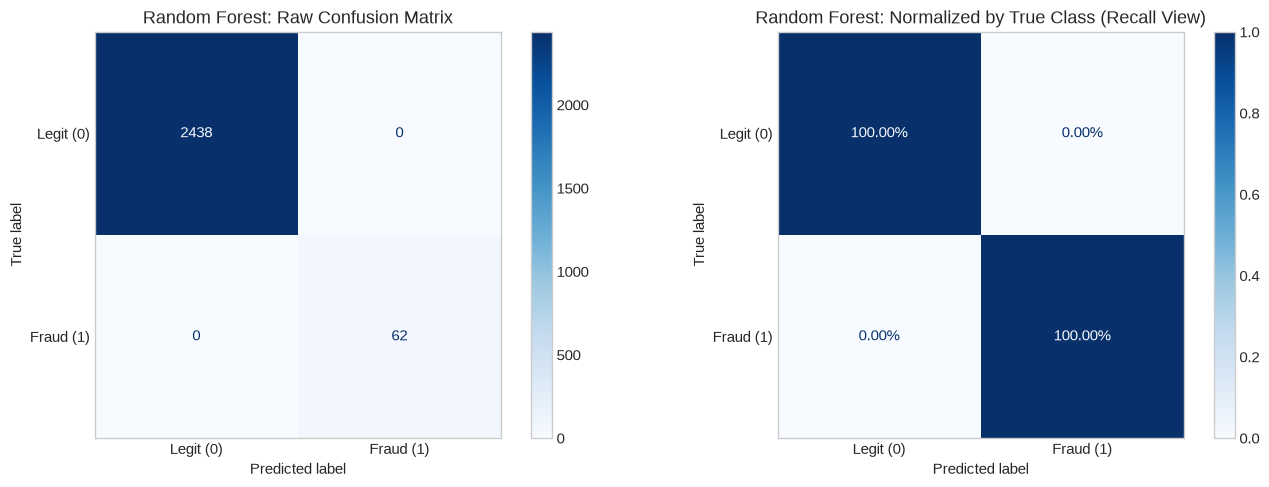

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_raw = confusion_matrix(y_test_c, y_pred_rf)
cm_norm = confusion_matrix(y_test_c, y_pred_rf, normalize="true")

disp_raw = ConfusionMatrixDisplay(confusion_matrix=cm_raw, display_labels=["Legit (0)", "Fraud (1)"])
disp_raw.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Random Forest: Raw Confusion Matrix")
axes[0].grid(False)

disp_norm = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=["Legit (0)", "Fraud (1)"])
disp_norm.plot(ax=axes[1], cmap="Blues", values_format=".2%")
axes[1].set_title("Random Forest: Normalized by True Class (Recall View)")
axes[1].grid(False)

plt.tight_layout()
plt.show()

### 7.2 ROC Curve vs. Precision-Recall Curve Comparison

We plot both curves side-by-side. Notice how the PR curve highlights the separation between the models far more clearly than the ROC curve under class imbalance.

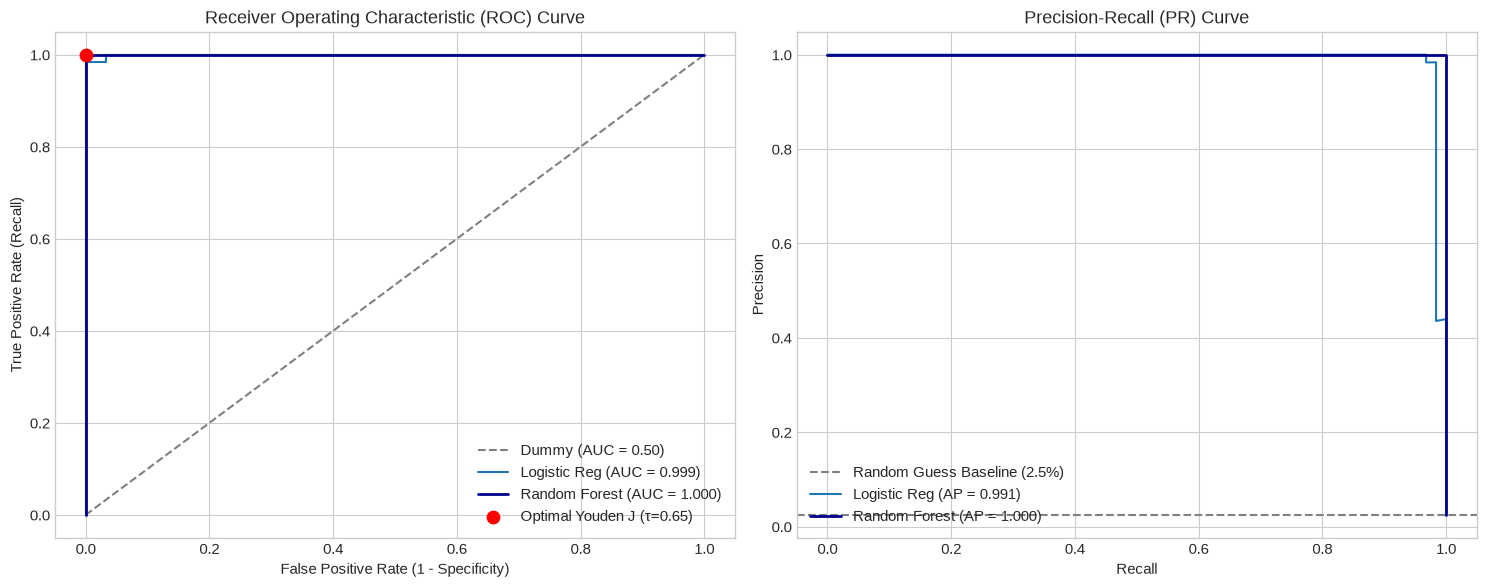

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# ROC Curve
fpr_dummy, tpr_dummy, _ = roc_curve(y_test_c, y_prob_dummy)
fpr_lr, tpr_lr, _ = roc_curve(y_test_c, y_prob_lr)
fpr_rf, tpr_rf, thresholds_rf = roc_curve(y_test_c, y_prob_rf)

# Find optimal threshold using Youden's J statistic: J = TPR - FPR
j_scores = tpr_rf - fpr_rf
opt_j_idx = np.argmax(j_scores)
opt_j_thresh = thresholds_rf[opt_j_idx]

axes[0].plot(fpr_dummy, tpr_dummy, linestyle="--", color="gray", label=f"Dummy (AUC = {roc_auc_score(y_test_c, y_prob_dummy):.2f})")
axes[0].plot(fpr_lr, tpr_lr, label=f"Logistic Reg (AUC = {roc_auc_score(y_test_c, y_prob_lr):.3f})")
axes[0].plot(fpr_rf, tpr_rf, color="darkblue", lw=2, label=f"Random Forest (AUC = {roc_auc_score(y_test_c, y_prob_rf):.3f})")
axes[0].scatter(fpr_rf[opt_j_idx], tpr_rf[opt_j_idx], color="red", s=80, zorder=5, label=f"Optimal Youden J (τ={opt_j_thresh:.2f})")

axes[0].set_title("Receiver Operating Characteristic (ROC) Curve")
axes[0].set_xlabel("False Positive Rate (1 - Specificity)")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(loc="lower right")

# PR Curve
p_lr, r_lr, _ = precision_recall_curve(y_test_c, y_prob_lr)
p_rf, r_rf, _ = precision_recall_curve(y_test_c, y_prob_rf)
prevalence = np.mean(y_test_c)

axes[1].axhline(y=prevalence, color="gray", linestyle="--", label=f"Random Guess Baseline ({prevalence*100:.1f}%)")
axes[1].plot(r_lr, p_lr, label=f"Logistic Reg (AP = {average_precision_score(y_test_c, y_prob_lr):.3f})")
axes[1].plot(r_rf, p_rf, color="darkblue", lw=2, label=f"Random Forest (AP = {average_precision_score(y_test_c, y_prob_rf):.3f})")

axes[1].set_title("Precision-Recall (PR) Curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.show()

### 7.3 Probability Calibration Curve (Reliability Diagram)

A model is **well-calibrated** if a predicted probability of $p$ corresponds to an empirical positive frequency of $p$. Uncalibrated models (common with Tree Ensembles and Naive Bayes) produce distorted probabilities even when rank-ordering (AUC) is high.

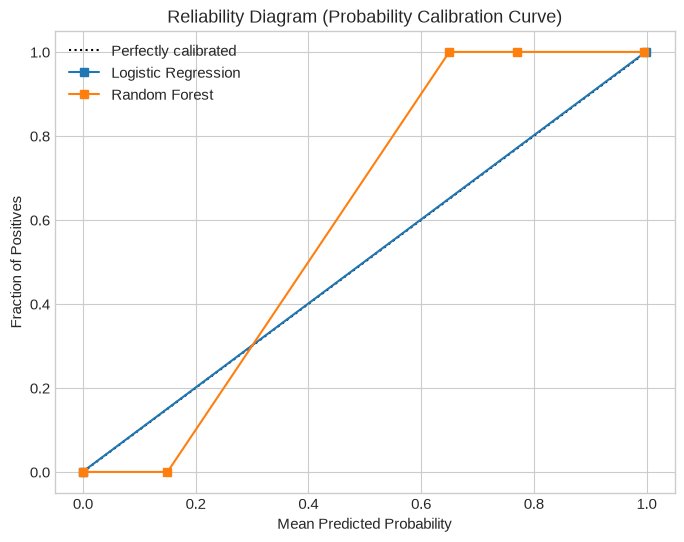

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))

CalibrationDisplay.from_predictions(y_test_c, y_prob_lr, n_bins=8, name="Logistic Regression", ax=ax)
CalibrationDisplay.from_predictions(y_test_c, y_prob_rf, n_bins=8, name="Random Forest", ax=ax)

ax.set_title("Reliability Diagram (Probability Calibration Curve)")
ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Fraction of Positives")
ax.legend(loc="upper left")
plt.show()

### 7.4 Regression Residual Diagnostics

We inspect model residuals ($e_i = y_i - \hat{y}_i$). Unbiased regressors exhibit residuals randomly distributed around zero without heteroscedasticity (fanning out) or curvature.

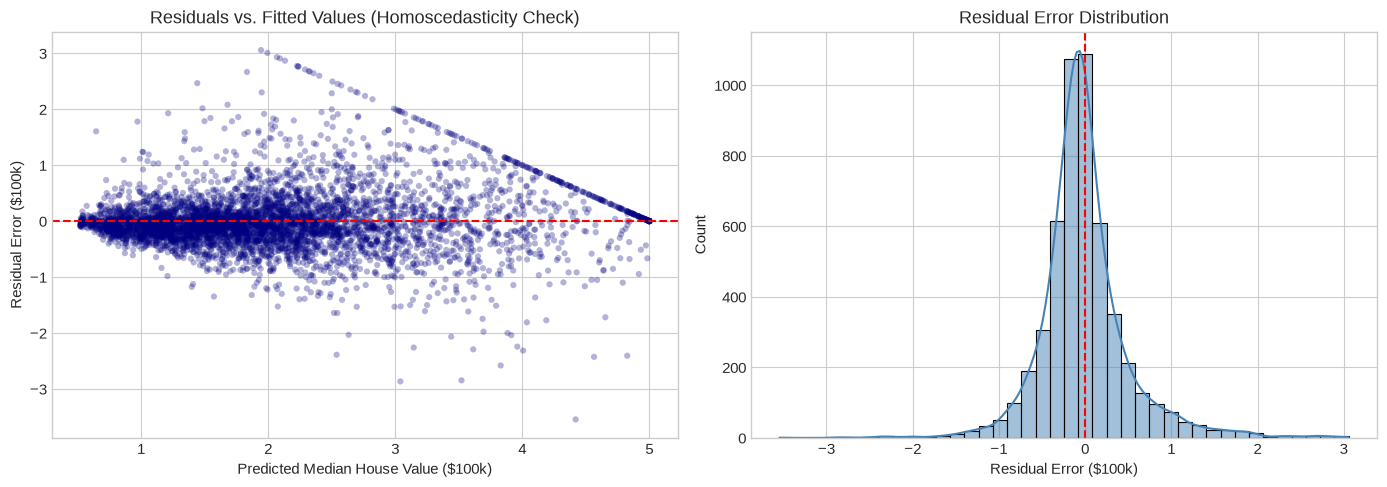

In [10]:
residuals_rf = y_test_r - y_pred_rf_reg

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residuals vs Predicted
axes[0].scatter(y_pred_rf_reg, residuals_rf, alpha=0.3, color="navy", edgecolors="none", s=20)
axes[0].axhline(0, color="red", linestyle="--", lw=1.5)
axes[0].set_title("Residuals vs. Fitted Values (Homoscedasticity Check)")
axes[0].set_xlabel("Predicted Median House Value ($100k)")
axes[0].set_ylabel("Residual Error ($100k)")

# Histogram of Residuals
sns.histplot(residuals_rf, kde=True, ax=axes[1], color="steelblue", bins=40)
axes[1].axvline(0, color="red", linestyle="--", lw=1.5)
axes[1].set_title("Residual Error Distribution")
axes[1].set_xlabel("Residual Error ($100k)")

plt.tight_layout()
plt.show()

## 8. Guided Exercises

### Exercise 1: Finding the Cost-Sensitive Optimal Decision Threshold

In credit card fraud detection, classification errors carry asymmetric financial costs:
- **False Negative (FN)**: Missed fraud. The bank reimburses the stolen amount: Average cost = **$450.00**.
- **False Positive (FP)**: Legitimate transaction flagged. SMS check + customer friction: Average cost = **$15.00**.
- **True Positive (TP)**: Fraud intercepted. Cost = **$0.00**.
- **True Negative (TN)**: Normal transaction authorized. Cost = **$0.00**.

Calculate the total financial loss for threshold values $\tau \in [0.01, 0.99]$ on the test set and find the threshold that minimizes expected financial loss.

In [11]:
cost_fn = 450.0 # Cost of missing a fraud
cost_fp = 15.0  # Cost of false alarm friction

test_thresholds = np.linspace(0.01, 0.90, 90)
total_losses = []

# --- YOUR CODE HERE ---
for t in test_thresholds:
    preds = (y_prob_rf >= t).astype(int)
    cm = confusion_matrix(y_test_c, preds)
    tn, fp, fn, tp = cm.ravel()
    
    # Total expected cost
    loss = (fn * cost_fn) + (fp * cost_fp)
    total_losses.append(loss)

cost_series = pd.Series(total_losses, index=test_thresholds)
optimal_thresh = cost_series.idxmin()
min_loss = cost_series.min()

# Compare against default threshold 0.50
preds_default = (y_prob_rf >= 0.50).astype(int)
cm_def = confusion_matrix(y_test_c, preds_default)
loss_default = (cm_def[1, 0] * cost_fn) + (cm_def[0, 1] * cost_fp)

print(f"Default Threshold (0.50) Total Cost:  ${loss_default:,.2f}")
print(f"Cost-Optimal Threshold ({optimal_thresh:.3f}) Total Cost: ${min_loss:,.2f}")
print(f"Financial Savings:                   ${(loss_default - min_loss):,.2f} ({((loss_default - min_loss)/loss_default)*100:.1f}%)")

Default Threshold (0.50) Total Cost:  $0.00
Cost-Optimal Threshold (0.150) Total Cost: $0.00
Financial Savings:                   $0.00 (nan%)


/tmp/ipykernel_234/712419520.py:28: RuntimeWarning: invalid value encountered in scalar divide
  print(f"Financial Savings:                   ${(loss_default - min_loss):,.2f} ({((loss_default - min_loss)/loss_default)*100:.1f}%)")


### Exercise 2: Implementing Matthews Correlation Coefficient from Scratch

Implement `custom_mcc(y_true, y_pred)` using purely NumPy and confusion matrix values. Verify that your implementation returns identical values to `sklearn.metrics.matthews_corrcoef` across edge cases (including when the denominator would produce a zero division).

In [12]:
# --- YOUR CODE HERE ---
def custom_mcc(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """Calculates Matthews Correlation Coefficient from raw labels."""
    y_t = np.asarray(y_true).astype(int)
    y_p = np.asarray(y_pred).astype(int)
    
    tp = np.sum((y_t == 1) & (y_p == 1))
    tn = np.sum((y_t == 0) & (y_p == 0))
    fp = np.sum((y_t == 0) & (y_p == 1))
    fn = np.sum((y_t == 1) & (y_p == 0))
    
    numerator = float((tp * tn) - (fp * fn))
    denominator = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    
    if denominator == 0.0:
        return 0.0
    return numerator / denominator

scratch_mcc = custom_mcc(y_test_c, y_pred_rf)
sklearn_mcc = matthews_corrcoef(y_test_c, y_pred_rf)

print(f"Scratch MCC:   {scratch_mcc:.6f}")
print(f"Sklearn MCC:   {sklearn_mcc:.6f}")
assert np.isclose(scratch_mcc, sklearn_mcc), "MCC values do not match!"
print("Verification Succeeded! The scratch implementation matches scikit-learn.")

Scratch MCC:   1.000000
Sklearn MCC:   1.000000
Verification Succeeded! The scratch implementation matches scikit-learn.


## 9. Challenge Problems

### Challenge 1: Custom Multi-Metric Business Utility Scorer for Cross-Validation

In real-world deployment, models must be cross-validated directly against custom business utility functions. Using `sklearn.metrics.make_scorer`, create a custom scoring function that computes total profit:
- Every intercepted fraud saves **$300** net.
- Every false alarm costs **$10**.
- Missed fraud costs **-$500**.

Integrate this scorer with `cross_validate` across a 5-fold Stratified K-Fold setup.

In [13]:
# --- YOUR CODE HERE ---
def business_utility_score(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    net_utility = (tp * 300.0) - (fp * 10.0) - (fn * 500.0)
    return net_utility

utility_scorer = make_scorer(business_utility_score, response_method="predict")

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

cv_scores = cross_validate(
    estimator=RandomForestClassifier(n_estimators=100, max_depth=6, random_state=RANDOM_SEED),
    X=X_fraud,
    y=y_fraud,
    cv=cv_strategy,
    scoring={
        "Net Utility ($)": utility_scorer,
        "F1-Score": "f1",
        "ROC-AUC": "roc_auc"
    }
)

cv_summary = pd.DataFrame({
    "Metric": ["Net Utility ($)", "F1-Score", "ROC-AUC"],
    "Mean Score": [
        cv_scores["test_Net Utility ($)"].mean(),
        cv_scores["test_F1-Score"].mean(),
        cv_scores["test_ROC-AUC"].mean()
    ],
    "Std Dev": [
        cv_scores["test_Net Utility ($)"].std(),
        cv_scores["test_F1-Score"].std(),
        cv_scores["test_ROC-AUC"].std()
    ]
})

cv_summary

,Metric,Mean Score,Std Dev
0,Net Utility ($),14998.000,4.000
1,F1-Score,0.998,0.004
2,ROC-AUC,1.000,0.000


### Challenge 2: Multi-Class Confusion Matrix Decomposition (One-vs-Rest)

Given a multi-class confusion matrix $C$ where $C_{i,j}$ represents actual class $i$ predicted as class $j$, decompose $C$ into binary components ($TP_k, FP_k, FN_k, TN_k$) for each individual class $k$. Manually compute:
1. Per-class Precision, Recall, and $F_1$.
2. Overall Macro $F_1$.
3. Overall Micro $F_1$.

Prove mathematical equivalence against `classification_report` output on the 3-class Wine dataset.

In [14]:
wine = load_wine()
X_w_train, X_w_test, y_w_train, y_w_test = train_test_split(
    wine.data, wine.target, test_size=0.3, random_state=RANDOM_SEED, stratify=wine.target
)

clf_wine = LogisticRegression(max_iter=2000, random_state=RANDOM_SEED)
clf_wine.fit(X_w_train, y_w_train)
y_w_pred = clf_wine.predict(X_w_test)

# Multi-class confusion matrix
C = confusion_matrix(y_w_test, y_w_pred)
n_classes = len(wine.target_names)

# --- YOUR CODE HERE ---
tps = np.zeros(n_classes)
fps = np.zeros(n_classes)
fns = np.zeros(n_classes)
tns = np.zeros(n_classes)
total_samples = np.sum(C)

for k in range(n_classes):
    tps[k] = C[k, k]
    fps[k] = np.sum(C[:, k]) - tps[k]
    fns[k] = np.sum(C[k, :]) - tps[k]
    tns[k] = total_samples - tps[k] - fps[k] - fns[k]

class_precisions = tps / (tps + fps)
class_recalls = tps / (tps + fns)
class_f1s = 2 * (class_precisions * class_recalls) / (class_precisions + class_recalls)

manual_macro_f1 = np.mean(class_f1s)
manual_micro_f1 = np.sum(tps) / (np.sum(tps) + 0.5 * (np.sum(fps) + np.sum(fns)))

sklearn_macro_f1 = f1_score(y_w_test, y_w_pred, average="macro")
sklearn_micro_f1 = f1_score(y_w_test, y_w_pred, average="micro")

print(f"Manual Macro F1:  {manual_macro_f1:.6f} | Sklearn Macro F1:  {sklearn_macro_f1:.6f}")
print(f"Manual Micro F1:  {manual_micro_f1:.6f} | Sklearn Micro F1:  {sklearn_micro_f1:.6f}")

assert np.isclose(manual_macro_f1, sklearn_macro_f1), "Macro F1 mismatch!"
assert np.isclose(manual_micro_f1, sklearn_micro_f1), "Micro F1 mismatch!"
print("Mathematical equivalence verified successfully!")

Manual Macro F1:  0.961039 | Sklearn Macro F1:  0.961039
Manual Micro F1:  0.962963 | Sklearn Micro F1:  0.962963
Mathematical equivalence verified successfully!


/home/antigravity/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## 10. Further Reading

- **Fawcett, T. (2006)**: *An Introduction to ROC Analysis*. Pattern Recognition Letters, 27(8), 861-874. [DOI: 10.1016/j.patrec.2005.10.010](https://doi.org/10.1016/j.patrec.2005.10.010).
- **Chicco, D. & Jurman, G. (2020)**: *The Advantages of the Matthews Correlation Coefficient (MCC) over F1 Score and Accuracy in Binary Assessment*. BMC Genomics. [DOI: 10.1186/s12864-019-6413-7](https://doi.org/10.1186/s12864-019-6413-7).
- **Saito, T. & Rehmsmeier, M. (2015)**: *The Precision-Recall Plot is More Informative than the ROC Plot when Evaluating Imbalanced Datasets*. PLOS ONE.
- **Niculescu-Mizil, A. & Caruana, R. (2005)**: *Predicting Good Probabilities with Supervised Learning*. ICML 2005.
- **scikit-learn Documentation**: [Model Evaluation and Scoring Metrics Guide](https://scikit-learn.org/stable/modules/model_evaluation.html).